In [1]:
# --.. ..- .-.. .-.. --- --.. ..- .-.. .-.. --- --.. ..- .-.. .-.. ---
# Z3ST: An open-source FEniCSx framework for thermo-mechanical analysis
# Author: Bianca Funaro
# Version: 0.4.1 (2026)
# --.. ..- .-.. .-.. --- --.. ..- .-.. .-.. --- --.. ..- .-.. .-.. ---

# Asymmetric temperatures on a hexagonal duct

The flats of the hexagonal shell are held at different temperatures; mechanically the duct is either fully free
or held only by `Clamp_z` on the bottom.
This notebook explains, step by step, the axial stress $\sigma_{zz}$, the bow and the end effects that z3st
computes, and checks each against a closed-form estimate.

**Boundary conditions** (`T_asymmetries/boundary_conditions.yaml`):

| | thermal | mechanical |
|---|---|---|
| `nord` (inner and outer face) | Dirichlet, $T = 600$ K | free |
| `sud` (inner and outer face) | Dirichlet, $T = 1700$ K | free |
| other flats, top | adiabatic | free |
| bottom | adiabatic | free, or `Clamp_z` ($u_z = 0$, $u_x$ and $u_y$ free) |

The rigid-body modes the BCs leave free are removed by `mechanical.remove_rigid_nullspace`, so the displacement
is defined up to those rigid motions and only relative displacements matter. The next cell tells which of the
two mechanical cases the stored run is.
Gravity is off (`mechanical.gravity` is not set; the default is 0).

All numbers are read from `output/fields.xdmf` through `gui_fields.load_grid`, so the notebook describes the
stored run. Material constants are those of `15_15Ti_local.yaml` (constant $E$, $\nu$, $\alpha$; $k(T)$ only
affects the temperature field).

> **How to read this notebook.** Each section gives the theory, the values recorded from the runs analysed so
> far (`Clamp_z` on the bottom, both ends free, then `Clamp_z` on a finer mesh), and a code cell that recomputes them from `output/`.
> Run the code cells only when no z3st run is writing `output/fields.h5`: the file cannot be read while the
> solver holds it.

In [2]:
import os
import sys

import matplotlib.pyplot as plt
import numpy as np

sys.path.insert(0, os.path.abspath("."))
from gui_fields import D, H, load_grid                       # noqa: E402
from plots import FLATS, local_coords, nearest, profile     # noqa: E402

E, NU, ALPHA, T_REF = 1.7e11, 0.3, 1.2e-5, 300.0     # 15_15Ti_local.yaml
EA = E * ALPHA / 1e6                                  # (MPa/K)

grid = load_grid()
cells = local_coords(grid.cell_centers().points)
nodes = local_coords(grid.points)
a_mid = 0.5 * (nodes["a"].min() + nodes["a"].max())
for f in (cells, nodes):
    f["xi"] = f["a"] - a_mid
cells.update(grid.cell_data)
cells["T (K)"] = grid.point_data["T (K)"][grid.cell_connectivity.reshape(-1, 8)].mean(1)
nodes.update(grid.point_data)

c = grid.cell_centers().points
area = grid.compute_cell_sizes(length=False, area=False)["Volume"] / (H / np.unique(np.round(c[:, 2], 9)).size)
mid_flat = np.abs(cells["s_frac"]) < 0.06              # cells next to mid-flat
print(f"D = {D:.3f} m, H = {H:.3f} m, {grid.n_cells} cells")
bottom = np.isclose(grid.points[:, 2], grid.points[:, 2].min())
CLAMPED = np.abs(grid.point_data["u"][bottom, 2]).max() < 1e-12
print("stored run:", "Clamp_z on the bottom (u_z = 0 there)" if CLAMPED else "both ends free")

D = 0.200 m, H = 1.000 m, 48000 cells
stored run: Clamp_z on the bottom (u_z = 0 there)


## 1. Temperature: $T = T(\theta)$

No condition depends on $z$ and the ends are adiabatic, so $T$ does not depend on $z$. On `nord` and `sud`
both faces are fixed, so $T$ is also uniform through the wall there. The heat enters at `sud`, runs around the
perimeter through the four side flats and leaves at `nord`: on the side flats $T$ falls along the flat, almost
linearly, and stays uniform through the thin wall.

The section therefore carries a temperature that varies only around the perimeter, the same at every height.

**Recorded (both runs, same thermal field).** $T$ = 600 K on `nord`, 1700 K on `sud`, 938 K at mid-flat on
`nord-est`/`nord-west`, 1472 K on `sud-est`/`sud-west`; constant along $z$ and through the wall. Area-weighted
mean over the section $\bar T$ = 1182 K.

Note: `nord` and `sud` group both the inner and the outer face of the flat, so the Dirichlet fixes $T$ over the whole
wall: there is no through-wall temperature gradient anywhere, only a gradient around the perimeter. If a
through-wall gradient is wanted, the BC must act on one face only.

### Section-average temperature $\bar T$

$\bar T = \sum_i A_i T_i / \sum_i A_i$ over the mid-height cell layer; $T$ does not vary with $z$, so it is also the
volume average. The six flats have equal area, so $\bar T$ is the mean of the six flat averages:
$$\bar T = \frac{600 + 2\cdot 929 + 2\cdot 1468 + 1700}{6} \approx 1182\ \text{K}.$$
(The mid-flat values, 938 and 1472 K, would give 1187 K: with $k(T)$, $T$ is not exactly linear along the side flats.)
$\bar T$ sets the free elongation $\Delta H = \alpha(\bar T - T_{ref})H \approx 10.6$ mm.

In [3]:
zc = np.unique(np.round(c[:, 2], 9))
layer = np.isclose(c[:, 2], zc[np.argmin(np.abs(zc - H / 2))])       # cell layer at mid-height
A_l, T_l, sec = area[layer], cells["T (K)"][layer], cells["sector"][layer]
print(f"{'flat':9s} {'area (mm2)':>10s} {'share':>6s} {'mean T':>8s} {'T along flat':>15s} {'A_i T_i / A':>12s}")
for m, name in enumerate(FLATS):
    k = sec == m
    print(f"{name:9s} {A_l[k].sum() * 1e6:10.1f} {A_l[k].sum() / A_l.sum():6.1%} "
          f"{np.sum(A_l[k] * T_l[k]) / A_l[k].sum():8.1f} {T_l[k].min():7.0f} .. {T_l[k].max():5.0f} "
          f"{np.sum(A_l[k] * T_l[k]) / A_l.sum():12.1f}")
print(f"{'total':9s} {A_l.sum() * 1e6:10.1f} {'100%':>6s} {np.sum(A_l * T_l) / A_l.sum():8.1f}")

flat      area (mm2)  share   mean T    T along flat  A_i T_i / A
nord-est       438.3  16.7%    929.4     615 ..  1213        154.9
nord           438.3  16.7%    600.1     600 ..   602        100.0
nord-west      438.3  16.7%    929.4     615 ..  1213        154.9
sud-west       438.3  16.7%   1467.8    1231 ..  1691        244.6
sud            438.3  16.7%   1699.9    1699 ..  1700        283.3
sud-est        438.3  16.7%   1467.8    1231 ..  1691        244.6
total         2629.9   100%   1182.4


variation of T along z on nord-est: 7.67e-10 K


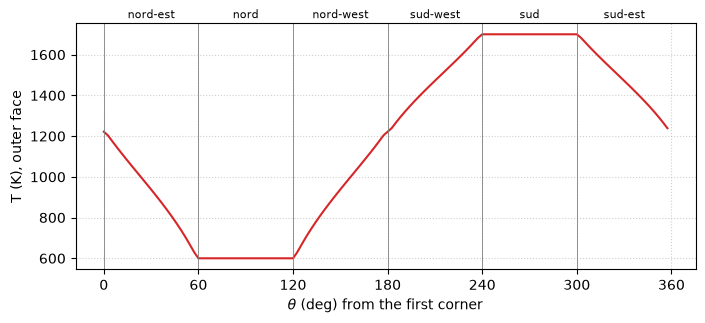

In [4]:
ring = nearest(nodes["z"], H / 2) & nearest(nodes["xi"], nodes["xi"].max())
th, T_th = profile(nodes, "theta", "T (K)", ring)
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(th, T_th, "-", color="tab:red")
for m, name in enumerate(FLATS):
    ax.axvline(60 * m, color="gray", lw=0.6)
    ax.text(60 * m + 30, 1.02, name, transform=ax.get_xaxis_transform(), ha="center", fontsize=8)
ax.set_xlabel(r"$\theta$ (deg) from the first corner"); ax.set_ylabel("T (K), outer face")
ax.set_xticks(np.arange(0, 361, 60)); ax.grid(ls=":", alpha=0.6)
z_spread = np.ptp(profile(nodes, "z", "T (K)", nearest(nodes["s_frac"], 0) & (nodes["sector"] == 0))[1])
print(f"variation of T along z on nord-est: {z_spread:.2e} K")

## 2. Axial stress: beam theory with plane sections

Far from the ends the duct behaves as a beam: each cross-section stays plane, so the total axial strain is a
plane over the section,
$$\varepsilon_{zz}(x, y) = \varepsilon_0 + b_x\,x + b_y\,y .$$
The free thermal strain $\alpha\,(T - T_{ref})$ follows $T(\theta)$, which is not a plane. Split the
temperature into its best-fit plane and a remainder,
$$T = T_{plane} + \Delta T, \qquad T_{plane} = T_0 + c_x\,x + c_y\,y \quad\text{(area-weighted least squares).}$$

* The plane part is absorbed **without stress**: $T_0$ gives a uniform elongation, $c_y$ a uniform curvature
  (the duct bows, section 3).
* The remainder cannot be followed by a plane section. With no axial load and no bending moment it is locked
  in as a self-equilibrated stress:
$$\boxed{\sigma_{zz} = -E\,\alpha\,\big(T - T_{plane}\big)}$$

What fixes the sign of $\sigma_{zz}$ on a flat is how much the beam stretches that flat compared with the flat's
own free expansion, not how hot the flat is. Three levels of restraint for the same $T$:

| restraint | imposed strain | $\sigma_{zz}$ |
|---|---|---|
| fully blocked | $0$ | $-E\alpha(T - T_{ref})$ |
| free elongation, no bending | uniform, $\alpha(\bar T - T_{ref})$ | $-E\alpha(T - \bar T)$ |
| free beam (this case) | plane, $\alpha(T_{plane} - T_{ref})$ | $-E\alpha(T - T_{plane})$ |

In [5]:
zc = np.unique(np.round(c[:, 2], 9))
layer = np.isclose(c[:, 2], zc[np.argmin(np.abs(zc - H / 2))])        # cell layer at mid-height
A, x, y, T = area[layer], c[layer, 0], c[layer, 1], cells["T (K)"][layer]
M = np.c_[np.ones(layer.sum()), x, y]
w = np.sqrt(A)
coef = np.linalg.lstsq(M * w[:, None], T * w, rcond=None)[0]
T_plane = M @ coef
T_mean = np.sum(A * T) / A.sum()
print(f"T_mean = {T_mean:.0f} K,  T_plane = {coef[0]:.0f} {coef[1]:+.1f} x {coef[2]:+.0f} y   (K, m)\n")

print(f"{'flat':9s} {'T':>6s} {'T_plane':>8s} {'T-T_plane':>9s} | {'blocked':>8s} {'elong.':>8s} {'free beam':>9s} {'z3st':>7s}  (MPa)")
rows = {}
for name in FLATS:
    m = mid_flat[layer] & (cells["sector"][layer] == FLATS.index(name))
    t, tp = T[m].mean(), T_plane[m].mean()
    fe = cells["sigma_zz (MPa)"][layer][m].mean()
    rows[name] = (t, tp, -EA * (t - tp), fe)
    print(f"{name:9s} {t:6.0f} {tp:8.0f} {t - tp:+9.0f} | {-EA * (t - T_REF):+8.0f} "
          f"{-EA * (t - T_mean):+8.0f} {-EA * (t - tp):+9.0f} {fe:+7.1f}")

T_mean = 1182 K,  T_plane = 1182 -0.0 x -6477 y   (K, m)

flat           T  T_plane T-T_plane |  blocked   elong. free beam    z3st  (MPa)
nord-est     938      909       +29 |    -1301     +499       -59   -53.7
nord         600      636       -36 |     -612    +1188       +74   +71.4
nord-west    938      909       +29 |    -1301     +499       -59   -53.6
sud-west    1472     1456       +16 |    -2390     -590       -33   -31.9
sud         1700     1729       -29 |    -2856    -1056       +59   +48.6
sud-est     1472     1456       +16 |    -2390     -590       -33   -32.1


**Why the hot `sud` flat is in tension.** Fully blocked, every flat is compressed and `sud` most of all. With free
elongation only, the flats hotter than the mean are compressed: `sud` would be at about $-1000$ MPa. The duct,
however, is also free to bend. The bending takes up the whole linear part of the `sud` → `nord` gradient, and the
plane imposes on `sud` the strain of a temperature *higher* than its own: the flat is stretched beyond its free
expansion and ends up in tension. The same holds, mirrored, for `nord`: it sits colder than the plane and is
also in tension.

The side flats are hotter than the plane, so they are compressed. The heat crosses the section only through
them, which makes $T(\theta)$ "bulge" on the sides compared with a straight line between 600 and 1700 K.

In short: the hot flat is on the convex, stretched side of the bend, and the bend is set by the whole section,
not by `sud` alone.

The signs agree everywhere. z3st gives lower magnitudes because the sampled section is within reach of a free
end and never fully reaches the plane-section regime (section 4), and because of a small parasitic bending stress of the linear elements
(section 5).

**Recorded, mid-height, mid-flat (both ends free).** $T_{plane} = 1182 - 6478\,y$ (K, $y$ in m).

| flat | $T$ (K) | $T_{plane}$ (K) | $T-T_{plane}$ | blocked | elongation only | free beam | z3st |
|---|---|---|---|---|---|---|---|
| `nord` | 600 | 636 | −36 | −612 | +1188 | **+73** | **+64.1** |
| `nord-est`, `nord-west` | 938 | 909 | +29 | −1301 | +499 | **−59** | **−48.2** |
| `sud-est`, `sud-west` | 1472 | 1456 | +16 | −2391 | −591 | **−33** | **−28.6** |
| `sud` | 1700 | 1729 | −29 | −2856 | −1056 | **+59** | **+38.2** |

(stresses in MPa, $E\alpha$ = 2.04 MPa/K, $T_{ref}$ = 300 K)

## 3. Free bending (bow) and elongation

From $\varepsilon_{zz} = \alpha\,(T_{plane} - T_{ref})$ with $T_{plane} = T_0 + c_y\,y$, and from the beam
kinematics $u_y = \kappa z^2/2$, $u_z = -\kappa\,y\,z$, $\varepsilon_{zz} = \varepsilon_0 - \kappa\,y$:
$$\kappa = -\alpha\,c_y, \qquad \text{sagitta } f = \frac{\kappa H^2}{8}, \qquad
\Delta H = \alpha\,(T_0 - T_{ref})\,H .$$
With $c_y < 0$ (hot side at $y < 0$) the curvature is positive: the duct is convex towards `sud`. None of this
generates stress, and `Clamp_z` on the bottom does not restrain it (a plane section rotating about the bottom
keeps $u_z = 0$ there). The sagitta is measured against the chord of the two ends, and the plot removes the
best-fit straight line (the rigid part), so the comparison holds for both mechanical cases.

**Recorded.**

| | `Clamp_z` on the bottom | both ends free | beam |
|---|---|---|---|
| curvature $\kappa$ (1/m) | 0.0774 | 0.0773 | 0.0777 |
| deflection | tip vs base 38.6 mm ($\kappa H^2/2$ = 38.7) | sagitta 9.6 mm ($\kappa H^2/8$ = 9.7) | |
| elongation $\Delta H$ | 10.6 mm | 10.6 mm (±5.3 per end) | 10.6 mm |
| end-section warping | 181 µm (top only) | 193 µm (both ends) | 0 (plane) |

The curvature is the same with and without the clamp: the bow is stress-free and `Clamp_z` does not restrain it.
z3st is 0.5 % below the beam value, the size of the parasitic-shear stiffening of section 5.

The displacement is symmetric: x → −x within 1.6 µm, z → H − z (free run) within 7 µm, on $|u|_{max}$ = 8.5 mm, with
no rotation about $z$. An apparently asymmetric deformed shape in the 3D view was a perspective effect of the
camera; the notebook `interactive_gui.ipynb` uses a parallel projection for the side view.

curvature   beam 0.0777 1/m   z3st 0.0774 1/m
sagitta     beam 9.72 mm   z3st 9.66 mm
elongation  beam 10.59 mm   z3st 10.59 mm


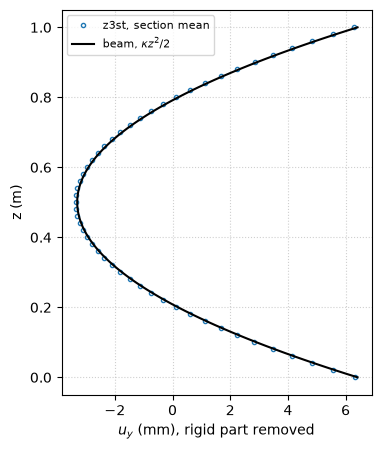

In [6]:
kappa = -ALPHA * coef[2]
u, p = grid.point_data["u"], grid.points
zs = np.unique(np.round(p[:, 2], 9))
uy = np.array([u[np.isclose(p[:, 2], z), 1].mean() for z in zs])
uz = np.array([u[np.isclose(p[:, 2], z), 2].mean() for z in zs])
kappa_fe = 2 * np.polyfit(zs, uy, 2)[0]
sag_fe = uy[np.argmin(np.abs(zs - H / 2))] - 0.5 * (uy[0] + uy[-1])
print(f"curvature   beam {kappa:.4f} 1/m   z3st {kappa_fe:.4f} 1/m")
print(f"sagitta     beam {kappa * H**2 / 8 * 1e3:.2f} mm   z3st {-sag_fe * 1e3:.2f} mm")
print(f"elongation  beam {ALPHA * (coef[0] - T_REF) * H * 1e3:.2f} mm   z3st {(uz[-1] - uz[0]) * 1e3:.2f} mm")

fig, ax = plt.subplots(figsize=(4, 5))
rigid = lambda z, v: v - np.polyval(np.polyfit(z, v, 1), z)        # remove the best-fit line
ax.plot(rigid(zs, uy) * 1e3, zs, "o", ms=3, mfc="none", label="z3st, section mean")
zz = np.linspace(0, H, 101)
ax.plot(rigid(zz, kappa * zz**2 / 2) * 1e3, zz, "k-", label=r"beam, $\kappa z^2/2$")
ax.set_xlabel(r"$u_y$ (mm), rigid part removed"); ax.set_ylabel("z (m)"); ax.grid(ls=":", alpha=0.6); ax.legend(fontsize=8)

## 4. The ends: Saint-Venant

At a free end the face must be traction-free, so $\sigma_{zz} = 0$ there: the end section warps out of plane
instead of staying plane. The self-equilibrated stress of section 2 is reached only away from the ends. In a
closed thin-walled section this decay length is long (of the order of a few diameters, not of the wall
thickness), because the warping is carried through shear in the walls.

* **Both ends free:** the profile is symmetric about $z = H/2$, zero at both ends, peaked at mid-height.
  The two decay zones overlap over 1 m, so the beam value is never fully reached.
* **`Clamp_z` on the bottom:** $u_z = 0$ with $u_x, u_y$ free is a mirror-symmetry plane. The model is half of a
  2 m duct with the bottom at its mid-plane: $\sigma_{zz}$ is largest at the bottom, zero at the free top, and
  closer to the beam value, because the bottom is 1 m from the only free end.

The cell prints which case the stored run is and draws the matching profile.

**Recorded, $\sigma_{zz}$ at mid-flat and mid-wall on `nord` (MPa):**

| z (m) | 0.01 | 0.14 | 0.26 | 0.29 | 0.49 | 0.74 | 0.89 | 0.99 |
|---|---|---|---|---|---|---|---|---|
| `Clamp_z` on the bottom | 82.1 | | | 80.3 | 72.9 | 50.4 | 29.2 | 0.1 |
| both ends free | 0.1 | 34.1 | 50.2 | | 64.1 | 47.4 | 29.3 | 0.1 |

Peaks: clamped bottom +82 / −57 / −37 / +56 MPa (`nord` / `nord-est` / `sud-est` / `sud`) at the bottom; free
+64 / −48 / −29 / +38 MPa at mid-height. The free duct sits 20–30 % lower: its mid-plane is only 0.5 m from each
free end, while the clamped model's mid-plane (the bottom) is 1 m from its only free end.

**Other components (free run).**

* $\sigma_{ss}$: through-wall plate bending of the flats (frame bending of the hexagon, from the different free
  lengths of the flats along $s$): `nord` +55 MPa inner face, −51 MPa outer, ≈ 0 at mid-wall. Along $z$ at mid-wall it
  is ≈ 0, except in the last cell at the ends (−30 MPa on `nord`, about +13 on the others), where the warping end
  section distorts the hexagon in its plane.
* $\sigma_{nn}$: about ±1 MPa inside the flats, up to ±4.5 MPa at the corners (θ = 60°, 120°, 180°), about −2.3 MPa at the
  ends of `sud`. The thin wall is in plane stress; at the corners the local frame turns, so "nn" partly holds the
  $\sigma_{ss}$ of the neighbouring flat. It weighs 1–2 % on von Mises.
* $\sigma_{vm}$: follows $\sigma_{zz}$ in the central part (62 MPa on `nord` at mid-height); the global maximum,
  98 MPa, is in the end cells, where the $\sigma_{ss}$ and $\sigma_{nn}$ peaks add (86 MPa at mid-height). These end
  values come from a single cell and depend on the mesh.
* Strains: dominated by $\alpha(T - T_{ref})$, about 0.0035 on `nord` to 0.017 on `sud`, constant along $z$; the
  mechanical part is small (≈ 3·10⁻⁴ between inner and outer face on `nord`).

warping of the end sections, out of their best plane (um): [  0. 183.]


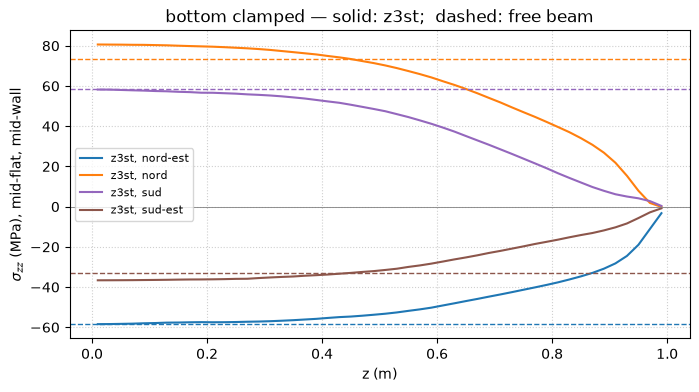

In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
colors = plt.cm.tab10(np.arange(len(FLATS)))
for m, name in enumerate(FLATS):
    if name.endswith("west"):
        continue                                  # mirror of the -est flat
    line = nearest(cells["s_frac"], 0) & nearest(cells["xi"], 0) & (cells["sector"] == m)
    zz, s = profile(cells, "z", "sigma_zz (MPa)", line)
    ax.plot(zz, s, "-", color=colors[m], label=f"z3st, {name}")
    ax.axhline(rows[name][2], color=colors[m], ls="--", lw=1)
ax.axhline(0, color="gray", lw=0.6)
ax.set_xlabel("z (m)"); ax.set_ylabel(r"$\sigma_{zz}$ (MPa), mid-flat, mid-wall")
ax.set_title(("bottom clamped" if CLAMPED else "both ends free") + " — solid: z3st;  dashed: free beam"); ax.grid(ls=":", alpha=0.6); ax.legend(fontsize=8)
end_warp = []
for z in (0.0, H):
    r = np.isclose(p[:, 2], z)
    Mz = np.c_[np.ones(r.sum()), p[r, 0], p[r, 1]]
    end_warp.append(np.abs(u[r, 2] - Mz @ np.linalg.lstsq(Mz, u[r, 2], rcond=None)[0]).max() * 1e6)
print("warping of the end sections, out of their best plane (um):", np.round(end_warp, 0))

## 5. Residual bending moment: parasitic shear of linear hexahedra

A free body carries no bending moment, so on every section $M_x = \int_A \sigma_{zz}\,y\,dA$ should vanish.
z3st gives a few hundred N·m, about constant along the duct. This was traced to the discretisation:

* the stresses written by z3st match a recomputation from the nodal $u$ and $T$, and the nodal force residual is
  $\sim 10^{-6}$ of the thermal loads: the FE solution *is* in equilibrium, and a direct solver gives the same
  moment;
* inside each layer of elements, $\sigma_{yz}$ has a near-zero resultant but varies linearly with $z$, and its
  moment about the layer centre balances $M_x$ exactly.

This is the **parasitic shear (shear locking)** of linear (Q1) hexahedra in bending.

In pure bending of a beam element of length $h$ (local coordinate $\zeta \in [-h/2, h/2]$ about its centre), plane
sections rotate by $\theta(\zeta) = \kappa\zeta$ and the axis deflects as $u_y = \kappa\zeta^2/2$, so that
$$\gamma_{yz} = \frac{\partial u_y}{\partial z} + \frac{\partial u_z}{\partial y} = \kappa\zeta - \kappa\zeta = 0 .$$
A Q1 element is linear in $\zeta$: it reproduces $u_z = -\kappa\,y\,\zeta$ exactly but replaces the parabola $u_y$ by
its chord, whose slope is zero. Then $\partial u_y/\partial z = 0$ and
$$\gamma_{yz}^{Q1} = -\kappa\,\zeta ,$$
zero at the element centre and largest at its faces. This shear does not exist in the real duct: it stores strain
energy $\propto G\kappa^2 h^2$ that resists the bending, so the element is too stiff. In the weak equilibrium that spurious shear carries a
spurious bending moment, which shows up as an extra $\sigma_{zz}$ linear in $y$:
$$\sigma_{zz}^{spur} = \frac{M_x\,y}{I_x}, \qquad I_x = \int_A y^2\,dA .$$
The element is slightly too stiff in bending: the spurious moment is a small fraction of $E I_x \kappa$ (the
moment that would block the bow), and the curvature is underestimated by about the same fraction.
Quadratic elements (`mechanical.order: 2`) or a finer mesh along $z$ reduce it.

**Recorded checks (free run).**

| check | result |
|---|---|
| $M_x$ per layer, cell centres | 683 N·m inside, 380 N·m in the end layers (clamped run: 683 N·m) |
| $M_x$ with 2×2×2 Gauss from nodal $u$, $T$ | 694 N·m: not a quadrature effect |
| stresses written vs recomputed | 1e-10 MPa: output consistent with $u$, $T$ and the material law |
| solver | `direct_mumps` gives 682 N·m, same as `iterative_amg` |
| nodal force residual | max 4 N vs thermal nodal loads up to 9·10⁵ N (4·10⁻⁶) |
| shear force per layer | a few N |
| $M_x$ including $\int\sigma_{yz}(z-z_c)$ inside each layer | 1390 N·m = $2M_x$: the in-layer $\sigma_{yz}$ moment is $-M_x$ |

**Spurious stress and corrected values (estimate, $I_x \approx 1.0\cdot10^{-5}$ m⁴):**

| flat | z3st | spurious $M_x y/I_x$ | corrected | free beam |
|---|---|---|---|---|
| `nord` | +64 | ≈ +6 | ≈ +58 | +73 |
| `nord-est`, `nord-west` | −48 | ≈ +3 | ≈ −51 | −59 |
| `sud-est`, `sud-west` | −29 | ≈ −3 | ≈ −26 | −33 |
| `sud` | +38 | ≈ −6 | ≈ +44 | +59 |

The parasitic shear exaggerates the `nord`/`sud` difference; $M_x$ is about 0.5 % of $E I_x\kappa \approx 1.4\cdot10^5$ N·m.

**Mesh refinement confirms it.** A third run (`Clamp_z` on the bottom, `mesh.geo` with `nt` 8, `nz` 50: element
height 20 mm instead of 25 mm) gives $M_x$ = 466 N·m at mid-height, 0.34 % of $E I_x\kappa$, against 683 N·m. A
parasitic-shear error scaling with the element height squared predicts $683\cdot(20/25)^2 \approx 437$ N·m. The
curvature rises from 0.0773–0.0774 to 0.0774 1/m (beam 0.0777) and the spurious stress on `nord`/`sud` drops to
about ±3.8 MPa.

**Quadratic elements remove it.** Same coarse mesh (`nt` 3, `nz` 40) and `Clamp_z`, with `mechanical.order: 2`:

| | Q1, `nt` 3 `nz` 40 | Q1, `nt` 8 `nz` 50 | Q2, `nt` 3 `nz` 40 | beam |
|---|---|---|---|---|
| $M_x$ at mid-height (N·m) | 683 | 466 | **15** | 0 |
| curvature (1/m) | 0.0774 | 0.0774 | **0.0777** | 0.0777 |

$\sigma_{zz}$ at mid-flat, mid-wall (MPa), `Clamp_z` runs:

| flat | Q1 coarse, $z$ = 0 | Q2, $z$ = 0 | Q1 coarse, $z$ = H/2 | Q2, $z$ = H/2 |
|---|---|---|---|---|
| `nord` | +82.1 | **+77.2** | +72.9 | **+63.1** |
| `nord-est` | −57.2 | **−60.3** | −52.5 | **−53.1** |
| `sud-est` | −37.7 | **−35.1** | −32.9 | **−28.1** |
| `sud` | +56.1 | **+62.4** | +46.8 | **+48.1** |

At the bottom the Q1 error follows the beam estimate $M_x y/I_x$ (about +5 on `nord`, −6 on `sud`). At mid-height it
does not: `nord` is off by about 10 MPa. The walls of the flats also bend (the frame bending of the hexagon,
$\sigma_{ss}$ of section 4), and three Q1 elements through the thickness lock in that plate bending as well, so the
global $M_x y/I_x$ correction captures only part of the error. The Q2 values are the reference.

In [8]:
Mx = np.array([np.sum(cells["sigma_zz (MPa)"][np.isclose(c[:, 2], z)] * 1e6
                      * area[np.isclose(c[:, 2], z)] * c[np.isclose(c[:, 2], z), 1]) for z in zc])
Ix = np.sum(A * y**2)
M_mid = Mx[np.argmin(np.abs(zc - H / 2))]
print(f"M_x per layer (N m): bottom {Mx[0]:.0f}, mid-height {M_mid:.0f}, top {Mx[-1]:.0f}")
print(f"I_x = {Ix:.3e} m^4,  E I_x kappa = {E * Ix * kappa:.3e} N m,  ratio = {M_mid / (E * Ix * kappa):.2%}")
print(f"\n{'flat':9s} {'z3st':>7s} {'spurious':>9s} {'corrected':>10s} {'free beam':>10s}  (MPa, mid-height)")
for name in FLATS:
    m = mid_flat[layer] & (cells["sector"][layer] == FLATS.index(name))
    spur = M_mid * y[m].mean() / Ix / 1e6
    print(f"{name:9s} {rows[name][3]:+7.1f} {spur:+9.1f} {rows[name][3] - spur:+10.1f} {rows[name][2]:+10.0f}")

M_x per layer (N m): bottom 423, mid-height 466, top 230
I_x = 1.040e-05 m^4,  E I_x kappa = 1.374e+05 N m,  ratio = 0.34%

flat         z3st  spurious  corrected  free beam  (MPa, mid-height)
nord-est    -53.7      +1.9      -55.6        -59
nord        +71.4      +3.8      +67.6        +74
nord-west   -53.6      +1.9      -55.4        -59
sud-west    -31.9      -1.9      -30.1        -33
sud         +48.6      -3.8      +52.3        +59
sud-est     -32.1      -1.9      -30.2        -33


## Open issues

1. **Parasitic shear (locking)**: resolved with `mechanical.order: 2` (section 5). Q1 stresses can be off by up to
   about 10 MPa; use Q2 for quantitative values. Q2 is slower: the coarse Q2 run reported 3.2·10⁵ s of wall time,
   inflated by the machine sleeping during the run, so its real cost is still to be measured.
2. **Mesh convergence** only started: the first two runs had `nt` 3 and `nz` 40, the third `nt` 8 and `nz` 50
   (residual moment 683 → 466 N·m). The end and corner values (σ_vm 98 MPa, σ_ss −30 MPa, σ_nn ±4.5 MPa, first
   mesh) come from single cells and still need a refinement study.
   `3d/geometry.yaml` still lists `nt: 3`, `nz: 40` while `mesh.geo` now defaults to 8 and 50: the post-processing
   reads the mesh from `output/`, so it is not affected, but the two files disagree.
3. **Through-wall gradient**: absent by construction, because `nord` and `sud` fix both faces (section 1).
4. **Post-processing leftovers**: `output/history.csv` and `output/profile_s.png` belong to the earlier slab
   benchmark run; the case `Allrun` does not call `plots.py`; `plots.py::plot_3d` still draws the deformed shape at
   about true scale (peak |u| = 5 % of D), while the notebook GUI uses 20 % of H.
5. Earlier statement corrected: gravity is **off** (opt-in `mechanical.gravity`, default 0), in both runs.

## Summary

* $T$ depends only on $\theta$. Its linear part makes the duct bow and elongate freely; only the departure from
  the best-fit plane is locked in as $\sigma_{zz} = -E\alpha(T - T_{plane})$.
* `nord` and `sud` are colder than the plane and in tension; the side flats are hotter than the plane and
  compressed. The hot flat is in tension because the bend stretches it beyond its free expansion.
* $\sigma_{zz}$ vanishes at a free end, where the section warps. With two free ends it peaks at mid-height, below
  the beam value, because the Saint-Venant zones overlap over the 1 m length; with `Clamp_z` on the bottom it peaks
  at the bottom, which acts as the mid-plane of a 2 m duct.
* The non-zero section moment is parasitic shear of the linear hexahedra. With `order: 2` it vanishes
  (683 → 15 N·m) and the curvature matches the beam value; Q1 $\sigma_{zz}$ is off by up to about 10 MPa.